# Data and exploratory analysis

Requires a built `features.parquet` (see `00_end_to_end.ipynb` or `python -m src.pipeline build`).

In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config, features, models, pipeline, simulation
from src import eda

## Combined data frame

In [2]:
df = features.load_modeling_frame()
print(df.shape)
df[["date", "symbol", "sector", "price"]].describe(include="all")

(1236778, 144)


,date,symbol,sector,price
count,1236778,1236778,1236778,1.236778e+06
unique,NaN,1756,21,NaN
top,NaN,AARTIIND,Unknown,NaN
freq,NaN,1832,559151,NaN
mean,2023-05-12 04:01:49.841539,NaN,NaN,1.491438e+03
min,2019-10-24 00:00:00,NaN,NaN,2.000000e+01
25%,2021-08-06 00:00:00,NaN,NaN,1.867725e+02
50%,2023-05-12 00:00:00,NaN,NaN,4.898500e+02
75%,2025-02-11 00:00:00,NaN,NaN,1.241300e+03
max,2026-11-20 00:00:00,NaN,NaN,1.622950e+05


## Feature sets

In [3]:
NUMERIC = features.numeric_columns(df)
DUMMIES = features.dummy_columns(df)
TO_PREDICT = features.TO_PREDICT
print(len(NUMERIC), len(DUMMIES), TO_PREDICT)

65 72 ['target_cls', 'target_reg']


In [4]:
pd.DataFrame({"feature": list(features.FEATURE_DOCS), "description": list(features.FEATURE_DOCS.values())}).head(20)

,feature,description
0,ret_1,One day return on the split-adjusted close.
1,ret_2,Two day return.
2,ret_3,Three day return.
3,ret_5,One trading week return.
4,ret_10,Two trading week return.
5,ret_21,One month momentum (21 trading days).
6,ret_63,Three month momentum.
7,ret_126,Six month momentum.
8,gap,Opening gap versus the previous adjusted close.
9,intraday_range,"High minus low divided by close, a daily volat..."


## Target distribution

In [5]:
describe, by_year, by_month = eda.target_summary(df)
describe

,target_reg
count,1.232984e+06
mean,8.798204e-12
std,5.554530e-02
min,-7.636288e-01
1%,-1.232984e-01
5%,-7.391929e-02
25%,-3.022945e-02
50%,-4.862387e-03
75%,2.414938e-02
95%,9.071471e-02


In [6]:
by_year

,rows,positive_rate,mean_forward_return,median_forward_return
date,,,,
2019,32694,0.267144,-7.492312e-11,-0.004446
2020,172508,0.302496,3.504259e-11,-0.006730
2021,175141,0.271233,5.316807e-11,-0.007577
2022,173637,0.282670,-2.765142e-11,-0.003818
2023,176314,0.261375,2.162981e-11,-0.004789
2024,177100,0.277826,-4.486873e-11,-0.005272
2025,170389,0.267969,-8.806996e-12,-0.002759
2026,155201,0.282769,1.704204e-11,-0.003693


## Correlation with the targets

In [7]:
result = eda.run_eda(df)
result["correlations"].head(20)

,feature,spearman_target_reg,spearman_target_cls,abs_corr
0,vol_63,-0.049236,0.050704,0.049236
1,atr_pct_14,-0.043430,0.062650,0.043430
2,vol_21,-0.043271,0.052281,0.043271
3,intraday_range,-0.042835,0.051084,0.042835
4,vol_5,-0.040623,0.042872,0.040623
5,cs_rank_vol_21,-0.039370,0.041917,0.039370
6,log_amihud_21,-0.037428,0.021222,0.037428
7,max_ret_21,-0.037018,0.042142,0.037018
8,cs_rank_deliv_per,0.035018,0.000113,0.035018
9,deliv_per,0.034697,0.001088,0.034697


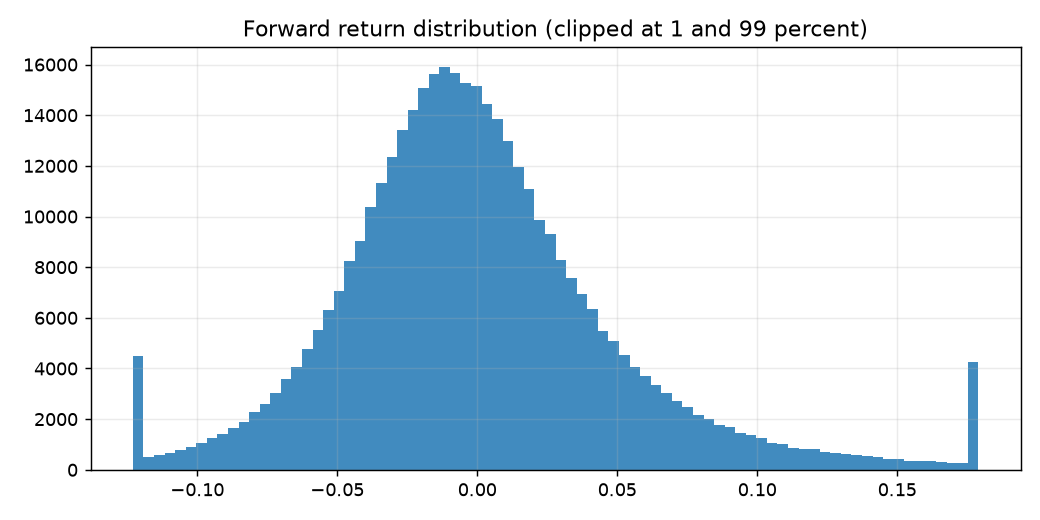

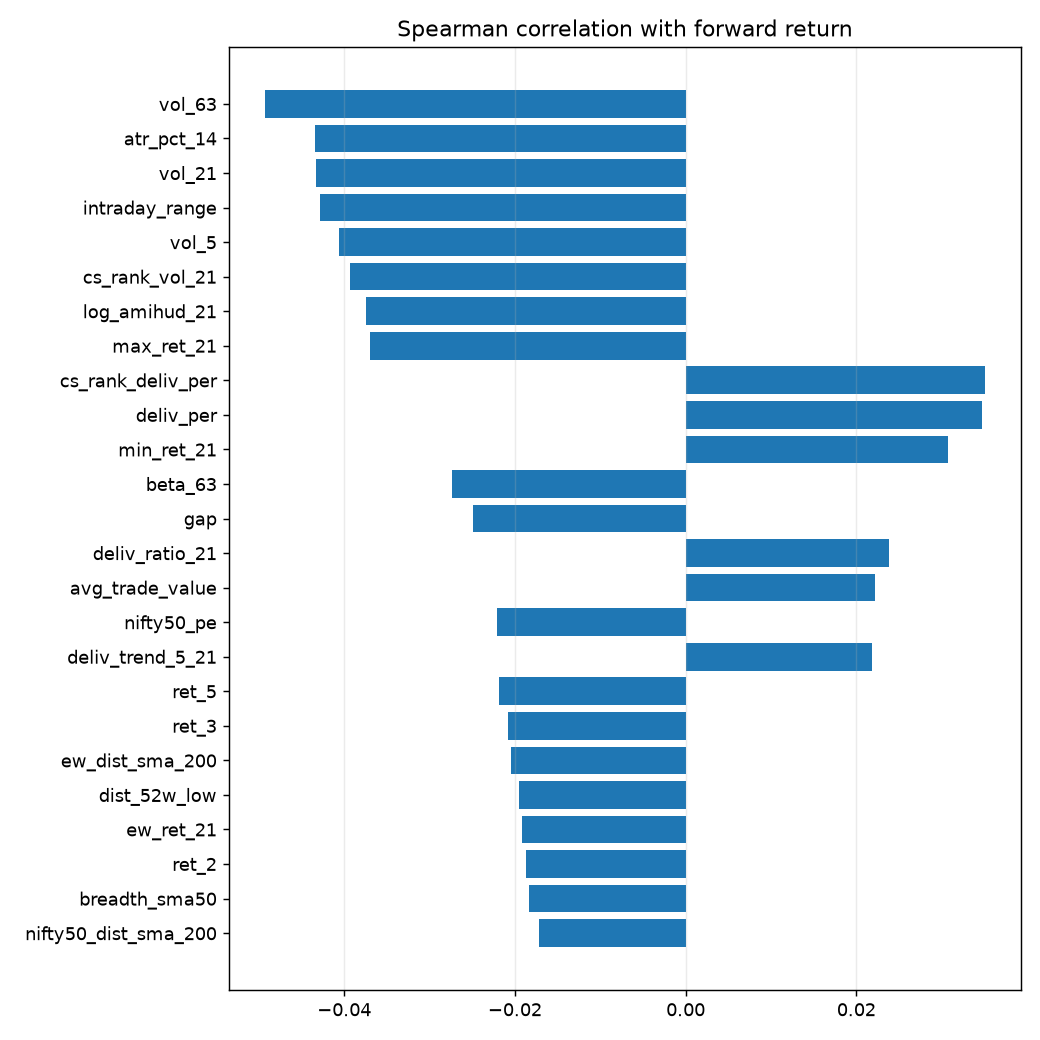

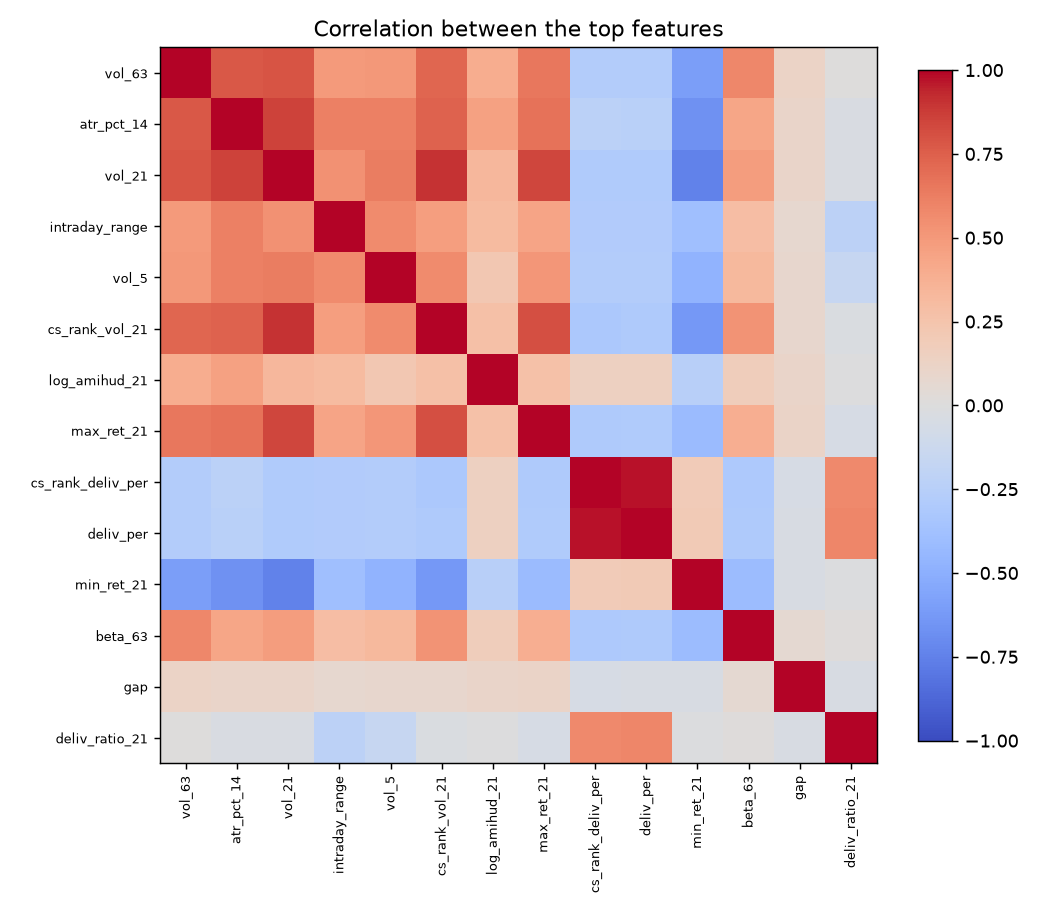

In [8]:
for name in ("eda_target_hist.png", "eda_top_correlations.png", "eda_correlation_heatmap.png"):
    display(Image(str(config.REPORT_DIR / name)))